# Week 10 — Object Detection Method

**Mata Kuliah:** Pengolahan Citra dan Visi Komputer (PCVK)
**Materi:** Modul 10 — Dasar-Dasar Deteksi Obyek

**Nama :** *Muhammad Ibnu Zauzi*
**NIM :** *244107020016*
**Kelas :** *TI-3A*

---

Notebook ini berisi pengerjaan **D1. Praktikum Deteksi Obyek Dasar** dan **D2. Praktikum Feature Matching dan Face Detection**.

| No | Materi | Metode |
|----|--------|--------|
| 1 | Template Matching | 6 metode `cv2.matchTemplate()` |
| 2 | Template Matching manual | Implementasi NumPy (tanpa OpenCV) untuk multiple object |
| 3 | Edge Detection | Sobel, Canny, Laplacian |
| 4 | Corner Detection | Harris, Shi-Tomasi |
| 5 | Grid Detection | Hough Transform |
| 6 | Contour Detection | `findContours()` |
| 7 | Face Detection | Haar Cascade |
| 8 | Cat Face Detection | Haar Cascade (cat face) |
| 9 | Eyes Detection | Haar Cascade (eye) |
| 10 | Smile Detection | Haar Cascade (smile) |
| 11 | Face Tracking | Google Colab + JavaScript |
| 12 | Face Blurring | `cv2.medianBlur()` |
| 13 | Olah gambar KTM | Image processing |
| 14 | Deteksi Obyek KTM | Feature Matching (SIFT + Homography) |

---
# D1. Praktikum Deteksi Obyek Dasar

## 1. Import Library dan Akses Folder Gambar

Langkah pertama sesuai modul: menyiapkan library dan mengakses folder gambar.

Pada Google Colab folder gambar biasanya diakses dari Google Drive. Karena notebook ini juga
bisa dijalankan secara lokal, path gambar ditentukan otomatis:

* jika dijalankan di **Google Colab** → folder Drive di-*mount* lebih dahulu,
* jika dijalankan **lokal** → memakai folder notebook itu sendiri (`BASE_DIR`).

In [1]:
# ============================================================
# 1. Import library dan akses folder gambar
# ============================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

%matplotlib inline

# --- tentukan folder kerja (Colab / lokal) -------------------
try:
    import google.colab                       # hanya ada di Google Colab
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/PCVK/minggu10'   # <- sesuaikan folder Drive Anda
    IN_COLAB = True
except ImportError:
    BASE_DIR = os.getcwd()                    # dijalankan secara lokal
    IN_COLAB = False

print('Google Colab :', IN_COLAB)
print('Folder kerja :', BASE_DIR)
print('Jumlah file  :', len(os.listdir(BASE_DIR)))

Google Colab : False
Folder kerja : C:\Kuliah\Semester5\PCVK\minggu10
Jumlah file  : 106


In [2]:
# --- helper: baca gambar dengan path relatif terhadap BASE_DIR ---
def path(nama):
    return os.path.join(BASE_DIR, nama)

def baca(nama, grayscale=False):
    flag = cv2.IMREAD_GRAYSCALE if grayscale else cv2.IMREAD_COLOR
    img = cv2.imread(path(nama), flag)
    if img is None:
        raise FileNotFoundError(f'Gambar "{nama}" tidak ditemukan di {BASE_DIR}')
    return img

def tampil(img, judul='', cmap=None, ukuran=(7, 5)):
    '''Menampilkan satu gambar dengan matplotlib.'''
    plt.figure(figsize=ukuran)
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap or 'gray')
    plt.title(judul)
    plt.axis('off')
    plt.show()

def tampil_baris(gambar, judul, ukuran=(16, 5), cmap=None):
    '''Menampilkan beberapa gambar dalam satu baris.'''
    n = len(gambar)
    fig, ax = plt.subplots(1, n, figsize=ukuran)
    if n == 1:
        ax = [ax]
    for a, im, t in zip(ax, gambar, judul):
        if im.ndim == 3:
            a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            a.imshow(im, cmap=cmap or 'gray')
        a.set_title(t, fontsize=11)
        a.axis('off')
    plt.tight_layout()
    plt.show()

# cek versi OpenCV (SIFT & CascadeClassifier membutuhkan OpenCV 4.x)
print('OpenCV', cv2.__version__)

OpenCV 4.10.0


## 2. Template Matching — 6 Metode pada OpenCV

**Citra masukan:** `cats_and_bunnies.jpg`  **Citra template:** `cat2_template.jpg`

Template adalah potongan gambar kucing pada citra masukan. Fungsi `cv2.matchTemplate()`
menggeser template ke seluruh area citra dan menyimpan skor kecocokan pada matriks hasil `R`.

| Metode | Skor terbaik |
|--------|--------------|
| `TM_SQDIFF`, `TM_SQDIFF_NORMED` | nilai **minimum** (paling kecil = paling mirip) |
| `TM_CCORR`, `TM_CCORR_NORMED` | nilai **maksimum** |
| `TM_CCOEFF`, `TM_CCOEFF_NORMED` | nilai **maksimum** |

Ukuran citra masukan : (829, 1024)
Ukuran citra template: (450, 340)


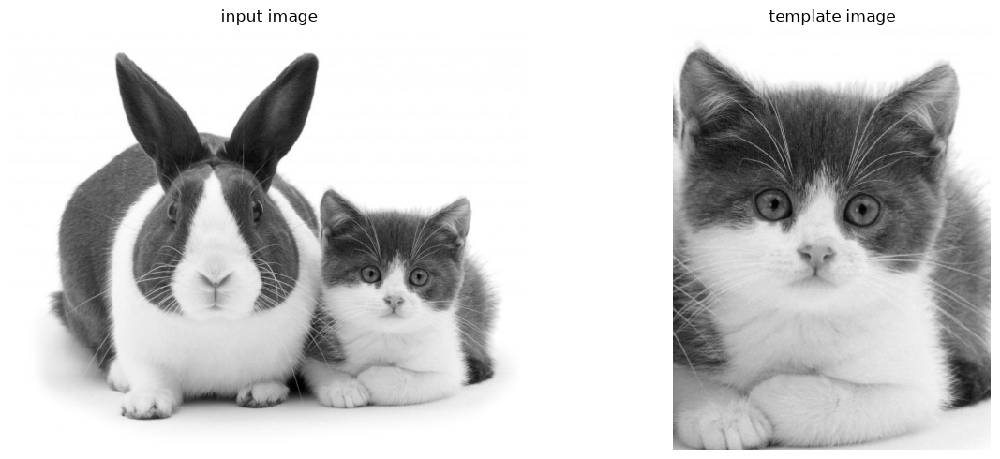

In [3]:
# ============================================================
# 2. Template Matching: 6 metode OpenCV
# ============================================================
img_bgr = baca('cats_and_bunnies.jpg')
tpl_bgr = baca('cat2_template.jpg')

# template matching umumnya dikerjakan pada citra grayscale
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
tpl_gray = cv2.cvtColor(tpl_bgr, cv2.COLOR_BGR2GRAY)

print('Ukuran citra masukan :', img_gray.shape)
print('Ukuran citra template:', tpl_gray.shape)

# tampilkan citra masukan & template
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(img_gray, cmap='gray'); ax[0].set_title('input image')
ax[1].imshow(tpl_gray, cmap='gray'); ax[1].set_title('template image')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

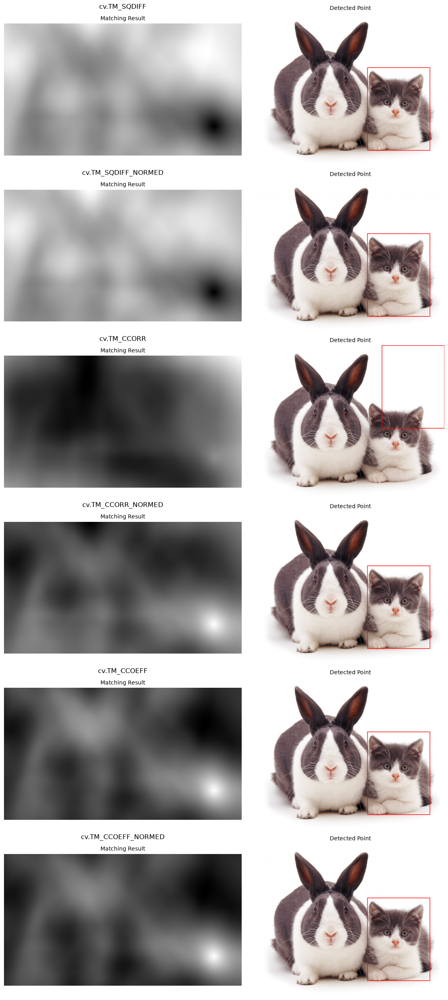

Metode                Lokasi (x, y)                   Skor
----------------------------------------------------------
cv.TM_SQDIFF          (605, 295)               251392.0000
cv.TM_SQDIFF_NORMED   (605, 295)                    0.0001
cv.TM_CCORR           (684, 0)             5859363840.0000
cv.TM_CCORR_NORMED    (605, 295)                    1.0000
cv.TM_CCOEFF          (605, 295)            691151296.0000
cv.TM_CCOEFF_NORMED   (605, 295)                    0.9998


In [4]:
# --- keenam metode matchTemplate ---------------------------------
metode = [
    ('cv.TM_SQDIFF',        cv2.TM_SQDIFF),
    ('cv.TM_SQDIFF_NORMED', cv2.TM_SQDIFF_NORMED),
    ('cv.TM_CCORR',         cv2.TM_CCORR),
    ('cv.TM_CCORR_NORMED',  cv2.TM_CCORR_NORMED),
    ('cv.TM_CCOEFF',        cv2.TM_CCOEFF),
    ('cv.TM_CCOEFF_NORMED', cv2.TM_CCOEFF_NORMED),
]

h, w = tpl_gray.shape
hasil = {}

fig, ax = plt.subplots(len(metode), 2, figsize=(12, 4.2 * len(metode)))

for baris, (nama, m) in enumerate(metode):
    # hitung matriks hasil R
    R = cv2.matchTemplate(img_gray, tpl_gray, m)

    # ambil lokasi terbaik
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(R)

    # SQDIFF -> semakin kecil semakin mirip, selain itu semakin besar semakin mirip
    if m in (cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED):
        top_left, skor = min_loc, min_val
    else:
        top_left, skor = max_loc, max_val

    bottom_right = (top_left[0] + w, top_left[1] + h)
    hasil[nama] = (top_left, skor)

    # --- gambar kiri: matriks hasil pencocokan
    ax[baris, 0].imshow(R, cmap='gray')
    ax[baris, 0].set_title('Matching Result', fontsize=10)
    ax[baris, 0].axis('off')

    # --- gambar kanan: titik yang terdeteksi
    deteksi = img_bgr.copy()
    cv2.rectangle(deteksi, top_left, bottom_right, (0, 0, 255), 2)
    ax[baris, 1].imshow(cv2.cvtColor(deteksi, cv2.COLOR_BGR2RGB))
    ax[baris, 1].set_title('Detected Point', fontsize=10)
    ax[baris, 1].axis('off')

    # judul metode untuk tiap pasang subplot
    ax[baris, 0].text(0.5, 1.10, nama, transform=ax[baris, 0].transAxes,
                      ha='center', va='bottom', fontsize=12)

plt.tight_layout()
plt.show()

# --- ringkasan skor ---------------------------------------------
print(f'{"Metode":<22}{"Lokasi (x, y)":<18}{"Skor":>18}')
print('-' * 58)
for nama, (lok, skor) in hasil.items():
    print(f'{nama:<22}{str(lok):<18}{skor:>18.4f}')

## 3. Template Matching Tanpa OpenCV — Multiple Object

Modul meminta konsep template matching **diimplementasikan sendiri tanpa `cv2.matchTemplate()`**,
dan harus mampu menemukan **banyak objek** pada satu citra.

**Citra masukan:** `bahrain.jpg`  **Citra template:** `bahrain-template.jpg`
(berisi satu pulau buatan di Bahrain yang muncul berulang pada citra).

### Dasar matematis

Yang dipakai adalah **Normalized Cross-Correlation (NCC)**:

$$R(x,y)=\frac{\sum_{i,j}\left(I(x+i,y+j)-\bar{I}_{xy}\right)\left(T(i,j)-\bar{T}\right)}
{\sqrt{\sum_{i,j}\left(I(x+i,y+j)-\bar{I}_{xy}\right)^{2}\sum_{i,j}\left(T(i,j)-\bar{T}\right)^{2}}}$$

Nilai `R` berada pada rentang **-1 sampai 1**; nilai mendekati 1 berarti sangat mirip.

### Strategi implementasi murni NumPy

1. **Integral image** (`cumsum` 2 arah) → menjumlahkan piksel pada jendela template dengan
   operasi *array* O(1) per posisi, tanpa loop piksel.
2. **Cross-correlation** dihitung lewat **FFT** (`np.fft.rfft2`) → konvolusi cepat untuk seluruh
   posisi sekaligus.
3. **Non-Maximum Suppression (NMS)** sederhana → membuang kotak yang saling tumpang tindih,
   sehingga diperoleh **multiple object**.

In [5]:
# ============================================================
# 3. Template Matching manual (NumPy saja) - multiple object
# ============================================================
# ---- helper murni NumPy (tidak memakai cv2.matchTemplate) ----

def to_gray(img):
    '''Konversi citra RGB (float 0-1 hasil plt.imread) ke grayscale 0-255.'''
    if img.ndim == 3:
        img = img[..., :3].astype(np.float64)
        return (0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]) * 255.0
    return img.astype(np.float64) * 255.0


def integral_image(a):
    '''Integral image: I(x,y) = jumlah piksel dari (0,0) sampai (x,y).'''
    return np.pad(np.cumsum(np.cumsum(a, axis=0), axis=1), ((1, 0), (1, 0)))


def window_sum(ii, h, w):
    '''Jumlah piksel tiap jendela h x w memakai integral image.'''
    return ii[h:, w:] - ii[:-h, w:] - ii[h:, :-w] + ii[:-h, :-w]


def correlate2d_fft(image, kernel):
    '''Cross-correlation 2D (mode valid) memakai FFT.'''
    H, W = image.shape
    h, w = kernel.shape
    fh, fw = H + h - 1, W + w - 1
    F = np.fft.rfft2(image, (fh, fw))
    K = np.fft.rfft2(kernel[::-1, ::-1], (fh, fw))     # balik kernel -> korelasi
    return np.fft.irfft2(F * K, (fh, fw))[h - 1:H, w - 1:W]


def ncc(image, templ):
    '''Normalized Cross-Correlation antara image dan templ.'''
    h, w = templ.shape
    s1 = window_sum(integral_image(image), h, w)          # jumlah I
    s2 = window_sum(integral_image(image ** 2), h, w)     # jumlah I^2
    tz = templ - templ.mean()                             # template zero-mean
    var = np.maximum(s2 - s1 ** 2 / (h * w), 1e-9)        # variansi tiap jendela
    return correlate2d_fft(image, tz) / np.sqrt(var * np.sum(tz ** 2))


def nms(skor, ambang, jarak_x, jarak_y):
    '''Non-Maximum Suppression sederhana -> multiple object tanpa kotak ganda.'''
    ys, xs = np.where(skor >= ambang)
    nilai = skor[ys, xs]
    titik = []
    for i in np.argsort(-nilai):
        x, y = int(xs[i]), int(ys[i])
        if all(abs(x - px) > jarak_x or abs(y - py) > jarak_y for px, py in titik):
            titik.append((x, y))
    return titik


# ---- muat citra (pakai plt.imread, bukan cv2.matchTemplate) ----
img_bahrain = to_gray(plt.imread(path('bahrain.jpg')))
tpl_bahrain = to_gray(plt.imread(path('bahrain-template.jpg')))

print('Citra masukan :', img_bahrain.shape)
print('Template      :', tpl_bahrain.shape)

# ---- hitung matriks NCC ----
R = ncc(img_bahrain, tpl_bahrain)
print('Ukuran matriks hasil R :', R.shape)
print('Skor maksimum          :', round(float(R.max()), 4))

Citra masukan : (586, 596)
Template      : (75, 80)
Ukuran matriks hasil R : (512, 517)
Skor maksimum          : 0.9995


Jumlah objek terdeteksi: 6
  objek 1: (x=395, y=215)  skor=1.000
  objek 2: (x=438, y=279)  skor=0.484
  objek 3: (x=344, y=476)  skor=0.454
  objek 4: (x=268, y=487)  skor=0.396
  objek 5: (x=413, y=426)  skor=0.393
  objek 6: (x=447, y=358)  skor=0.381


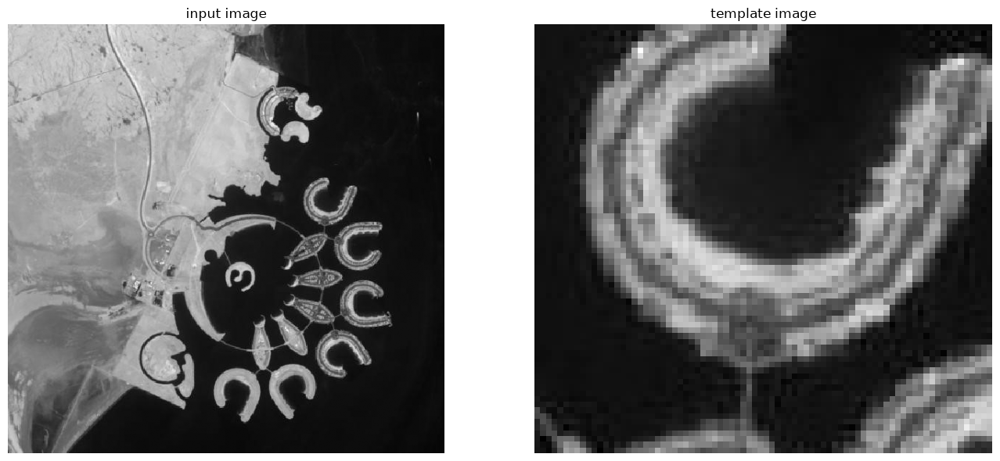

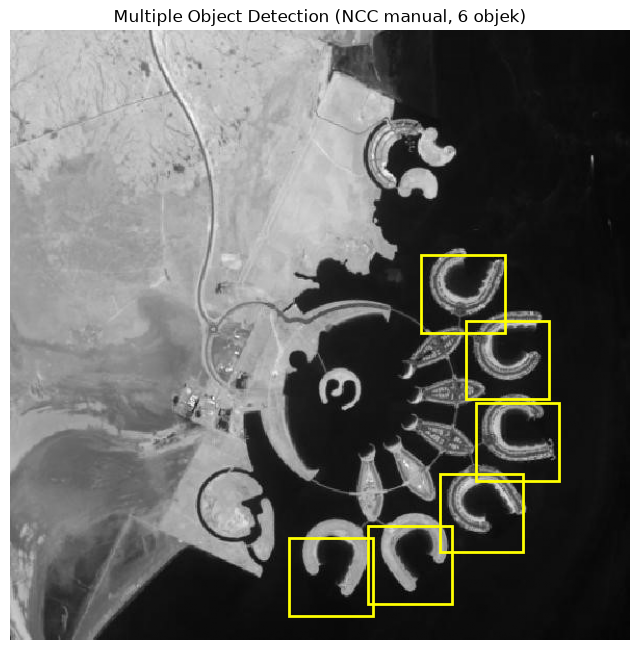

In [6]:
# ---- deteksi multiple object + visualisasi ----
th, tw = tpl_bahrain.shape
AMBANG = 0.32          # ambang kemiripan
titik = nms(R, AMBANG, tw * 0.8, th * 0.8)

print(f'Jumlah objek terdeteksi: {len(titik)}')
for i, (x, y) in enumerate(titik, 1):
    print(f'  objek {i}: (x={x:3d}, y={y:3d})  skor={R[y, x]:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(img_bahrain, cmap='gray'); ax[0].set_title('input image'); ax[0].axis('off')
ax[1].imshow(tpl_bahrain, cmap='gray'); ax[1].set_title('template image'); ax[1].axis('off')
plt.tight_layout()
plt.show()

# tampilkan hasil deteksi
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img_bahrain, cmap='gray')
for (x, y) in titik:
    ax.add_patch(Rectangle((x, y), tw, th, fill=False, edgecolor='yellow', linewidth=2))
ax.set_title(f'Multiple Object Detection (NCC manual, {len(titik)} objek)')
ax.axis('off')
plt.show()

## 4. Edge Detection — Sobel, Canny, Laplacian

**Citra masukan:** `parking-lot-cars.jpg`

* **Sobel** — menghitung gradien intensitas arah X dan Y dengan kernel 3×3, lalu digabung
  dengan `cv2.magnitude()`.
* **Canny** — 4 tahap: Gaussian filter → gradien Sobel → *non-maximum suppression* →
  *hysteresis thresholding*.
* **Laplacian** — turunan kedua citra dengan kernel 3×3; citra dihaluskan (Gaussian) lebih dahulu
  karena metode ini sangat sensitif terhadap noise.

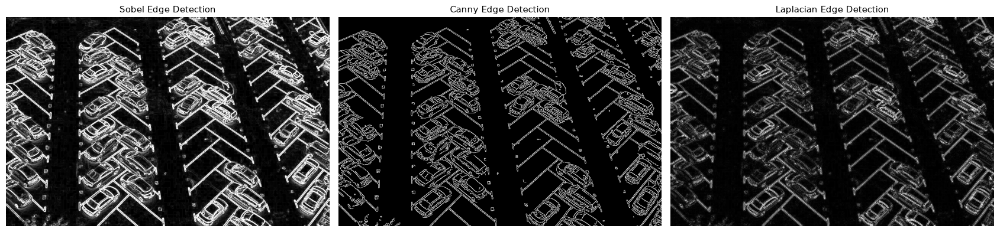

Jumlah piksel tepi:
  Sobel     : 159541
  Canny     : 53954
  Laplacian : 92752


In [7]:
# ============================================================
# 4. Edge Detection: Sobel, Canny, Laplacian
# ============================================================
img = baca('parking-lot-cars.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# ---------- Sobel ----------
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)   # gradien arah X
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)   # gradien arah Y
sobel = cv2.magnitude(sobel_x, sobel_y)                # gabungan gradien
sobel = cv2.convertScaleAbs(sobel)                     # ubah ke uint8

# ---------- Canny ----------
canny = cv2.Canny(gray, threshold1=100, threshold2=200)

# ---------- Laplacian ----------
blur = cv2.GaussianBlur(gray, (3, 3), 0)               # haluskan dulu anti-noise
laplacian = cv2.Laplacian(blur, cv2.CV_64F, ksize=3)
laplacian = cv2.convertScaleAbs(laplacian)

tampil_baris([sobel, canny, laplacian],
             ['Sobel Edge Detection', 'Canny Edge Detection', 'Laplacian Edge Detection'],
             ukuran=(17, 5))

print('Jumlah piksel tepi:')
print('  Sobel     :', int((sobel > 50).sum()))
print('  Canny     :', int((canny > 0).sum()))
print('  Laplacian :', int((laplacian > 50).sum()))

## 5. Corner Detection — Harris dan Shi-Tomasi

**Citra masukan:** `chess-board.jpg`

* **Harris** — `cv2.cornerHarris(src, blockSize, ksize, k)`. Nilai respons `R` besar menandakan
  sudut. Di sini ditambahkan **non-maximum suppression** supaya tiap persilangan papan hanya
  menghasilkan satu titik (tanpa marker tebal).
* **Shi-Tomasi** — `cv2.goodFeaturesToTrack()`. Hanya memakai nilai eigen minimum (`λmin`),
  lalu mengambil N sudut terkuat dengan jarak minimum antar sudut.

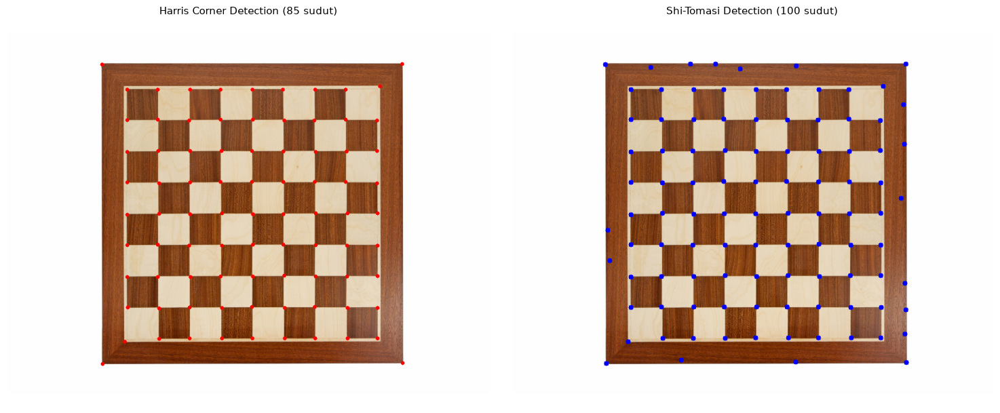

In [8]:
# ============================================================
# 5. Corner Detection: Harris dan Shi-Tomasi
# ============================================================
board = baca('chess-board.jpg')
board_gray = cv2.cvtColor(board, cv2.COLOR_BGR2GRAY)

# ---------- Harris Corner Detection ----------
dst = cv2.cornerHarris(np.float32(board_gray), blockSize=2, ksize=3, k=0.04)
dst_norm = cv2.normalize(dst, None, 0, 255, cv2.NORM_MINMAX)

def nms_poin(skor, mask, radius):
    '''Ambil titik terkuat saja dalam radius tertentu.'''
    titik = []
    ys, xs = np.where(mask)
    for i in np.argsort(-skor[ys, xs]):
        x, y = xs[i], ys[i]
        if all((x - px) ** 2 + (y - py) ** 2 > radius ** 2 for px, py in titik):
            titik.append((int(x), int(y)))
    return titik

mask_harris = dst > 0.02 * dst.max()
titik_harris = nms_poin(dst, mask_harris, radius=25)

harris_img = board.copy()
for (x, y) in titik_harris:
    cv2.circle(harris_img, (x, y), 4, (0, 0, 255), -1)     # merah (BGR)

# ---------- Shi-Tomasi Corner Detection ----------
sudut = cv2.goodFeaturesToTrack(board_gray,
                                maxCorners=100,
                                qualityLevel=0.01,
                                minDistance=50)
sudut = np.intp(sudut)

shi_img = board.copy()
for i in sudut:
    x, y = i.ravel()
    cv2.circle(shi_img, (int(x), int(y)), 5, (255, 0, 0), -1)   # biru (BGR)

tampil_baris([harris_img, shi_img],
             [f'Harris Corner Detection ({len(titik_harris)} sudut)',
              f'Shi-Tomasi Detection ({len(sudut)} sudut)'],
             ukuran=(15, 6))

## 6. Grid Detection — Hough Transform

**Citra masukan:** `sudoku.jpg`

Tahapan grid detection sesuai teori:

1. **Canny Edge Detection** untuk memperoleh tepi.
2. **Dilasi** — Canny mendeteksi dua sisi sebuah garis grid sebagai dua tepi berbeda;
   dilasi menyatukan keduanya.
3. **Erosi** — setelah dilasi garis menjadi tebal sehingga Hough mendeteksi banyak garis;
   erosi menipiskannya kembali.
4. **`cv2.HoughLines()`** untuk mendeteksi garis lurus.
5. **Menggabungkan garis yang mirip** (*similar*) dalam dua tahap:
   pertama berdasarkan **orientasi `θ`** (ambil 2 arah dominan), lalu berdasarkan
   **jarak `ρ`** yang berdekatan. Tanpa penggabungan ini, satu garis tebal akan terdeteksi
   berkali-kali sehingga hasilnya tampak berantakan.

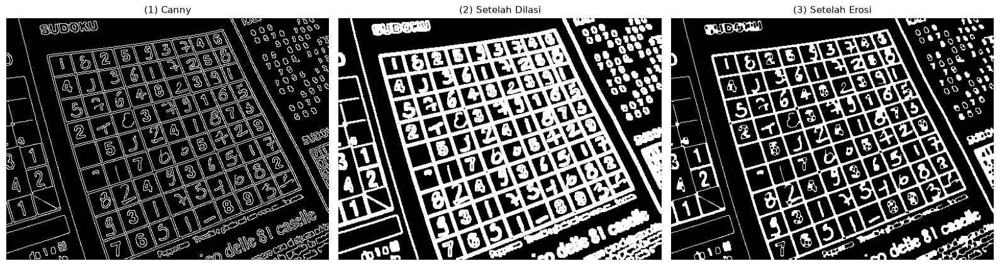

Garis terdeteksi (mentah): 85


In [9]:
# ============================================================
# 6. Grid Detection dengan Hough Transform
# ============================================================
sudoku = baca('sudoku.jpg')
sudoku_gray = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)

# (1) Canny edge detection
edges = cv2.Canny(sudoku_gray, 50, 150, apertureSize=3)

# (2) dilasi  (3) erosi
kernel = np.ones((3, 3), np.uint8)
edges_dilasi = cv2.dilate(edges, kernel, iterations=1)
edges_rapi = cv2.erode(edges_dilasi, kernel, iterations=1)

tampil_baris([edges, edges_dilasi, edges_rapi],
             ['(1) Canny', '(2) Setelah Dilasi', '(3) Setelah Erosi'],
             ukuran=(16, 5))

# (4) Hough Transform
garis = cv2.HoughLines(edges_rapi, rho=1, theta=np.pi / 180, threshold=230)
garis = garis[:, 0]
print('Garis terdeteksi (mentah):', len(garis))

Ukuran tiap grup orientasi: [30, 29, 18, 4, 4]
  theta ~  73.8 deg -> 10 garis
  theta ~ 158.6 deg -> 10 garis
Garis setelah penggabungan: 20


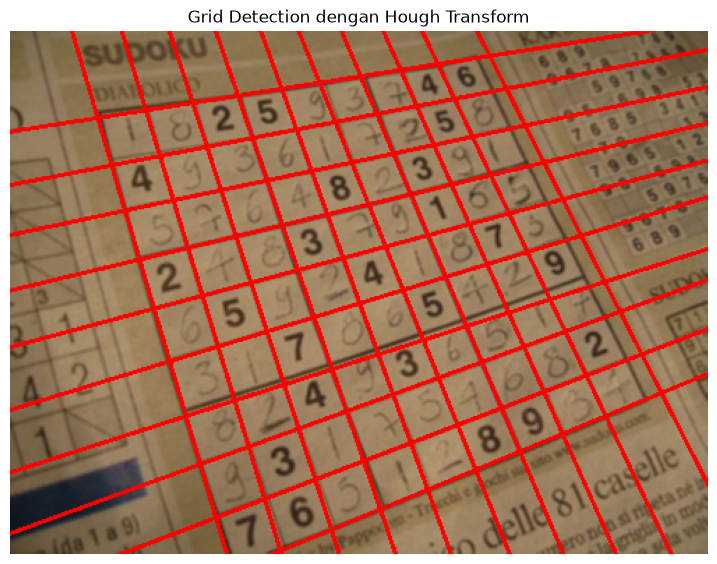

In [10]:
# (5) gabungkan garis yang mirip
def gabung_theta(garis, toleransi=np.deg2rad(8)):
    '''Kelompokkan garis berdasarkan orientasi (theta) -> ambil arah dominan.'''
    grup = []
    for rho, theta in garis:
        for g in grup:
            if abs(g['theta'] - theta) <= toleransi:
                g['item'].append((rho, theta))
                g['theta'] = np.mean([t for _, t in g['item']])
                break
        else:
            grup.append({'theta': theta, 'item': [(rho, theta)]})
    grup.sort(key=lambda g: -len(g['item']))          # terbesar lebih dahulu
    return grup


def gabung_rho(item, toleransi=12):
    '''Gabungkan garis dengan rho berdekatan menjadi satu garis wakil.'''
    item = sorted(item, key=lambda t: t[0])
    kelompok = [[item[0]]]
    for it in item[1:]:
        if it[0] - kelompok[-1][-1][0] <= toleransi:
            kelompok[-1].append(it)
        else:
            kelompok.append([it])
    return [(float(np.mean([r for r, _ in c])), float(np.mean([t for _, t in c])))
            for c in kelompok]


grup_theta = gabung_theta(garis)
print('Ukuran tiap grup orientasi:', [len(g['item']) for g in grup_theta])

garis_gabung = []
for g in grup_theta[:2]:                              # ambil 2 arah dominan
    hasil = gabung_rho(g['item'])
    print(f"  theta ~ {np.rad2deg(g['theta']):5.1f} deg -> {len(hasil)} garis")
    garis_gabung += hasil

print('Garis setelah penggabungan:', len(garis_gabung))

# gambar garis pada citra
hasil_grid = sudoku.copy()
for rho, theta in garis_gabung:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    x1, y1 = int(x0 + 2000 * (-b)), int(y0 + 2000 * a)
    x2, y2 = int(x0 - 2000 * (-b)), int(y0 - 2000 * a)
    cv2.line(hasil_grid, (x1, y1), (x2, y2), (0, 0, 255), 2)

tampil(hasil_grid, 'Grid Detection dengan Hough Transform', ukuran=(9, 7))

## 7. Contour Detection

**Citra masukan:** `laptop.jpg`

Kontur adalah kurva tertutup yang menghubungkan titik-titik kontinu dengan warna/intensitas sama.
Tahapannya:

1. Ubah citra menjadi **biner** (di sini memakai Canny edge detection).
2. `cv2.findContours()` dengan mode `RETR_LIST` dan `CHAIN_APPROX_SIMPLE`.
3. `cv2.drawContours()` untuk menggambar kontur pada citra.

Jumlah kontur ditemukan: 231
10 luas kontur terbesar: [41043, 38837, 26279, 15044, 14835, 14687, 14505, 13640, 13429, 13306]


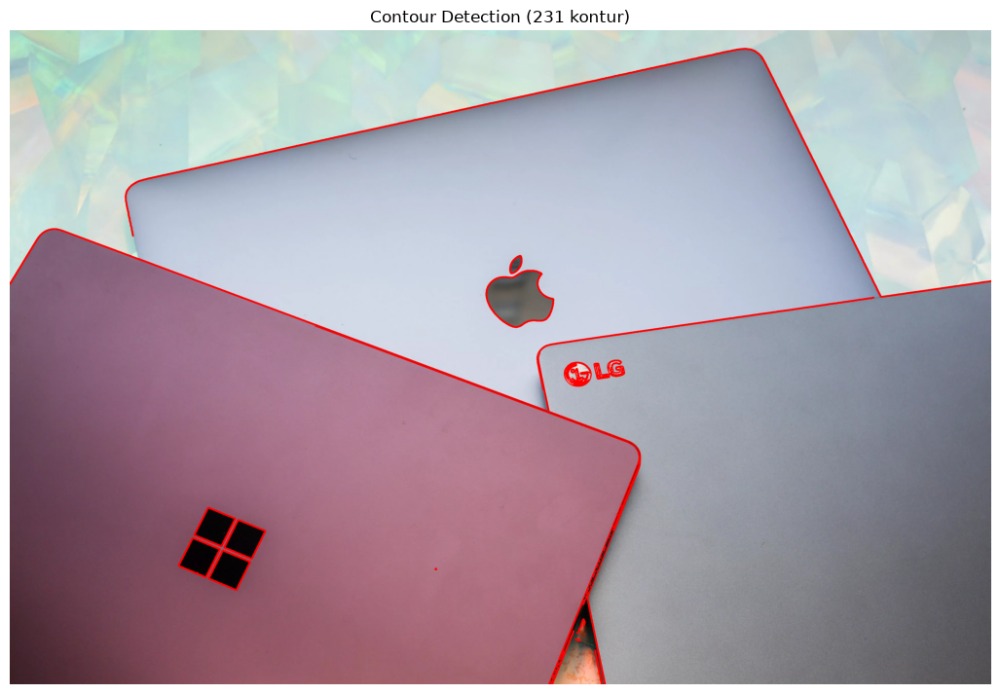

In [11]:
# ============================================================
# 7. Contour Detection dengan findContours()
# ============================================================
laptop = baca('laptop.jpg')
laptop_gray = cv2.cvtColor(laptop, cv2.COLOR_BGR2GRAY)

# (1) citra biner
laptop_edges = cv2.Canny(cv2.GaussianBlur(laptop_gray, (5, 5), 0), 50, 150)
laptop_edges = cv2.dilate(laptop_edges, np.ones((3, 3), np.uint8), iterations=1)

# (2) temukan kontur
kontur, hierarki = cv2.findContours(laptop_edges,
                                    cv2.RETR_LIST,
                                    cv2.CHAIN_APPROX_SIMPLE)
print('Jumlah kontur ditemukan:', len(kontur))

# statistik luas kontur
luas = sorted((cv2.contourArea(c) for c in kontur), reverse=True)
print('10 luas kontur terbesar:', [int(a) for a in luas[:10]])

# (3) gambar kontur
hasil_kontur = laptop.copy()
cv2.drawContours(hasil_kontur, kontur, -1, (0, 0, 255), 3)

tampil(hasil_kontur, f'Contour Detection ({len(kontur)} kontur)', ukuran=(13, 9))

---
# D2. Praktikum Feature Matching dan Face Detection

## 8. Menyiapkan Haar Cascade

OpenCV menyediakan *pretrained feature* dalam format XML (algoritma Viola-Jones).
File yang dipakai:

| File XML | Kegunaan |
|----------|----------|
| `haarcascade_frontalface_alt.xml` | wajah manusia |
| `haarcascade_frontalcatface.xml` | wajah kucing |
| `haarcascade_eye.xml` | mata |
| `haarcascade_smile.xml` | senyuman |

Jika file XML belum tersedia di folder `haarcascades/`, notebook akan mengunduhnya otomatis
dari repositori resmi OpenCV.

In [12]:
# ============================================================
# 8. Muat pretrained Haar Cascade
# ============================================================
import urllib.request

FOLDER_XML = path('haarcascades')
os.makedirs(FOLDER_XML, exist_ok=True)

SUMBER = 'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/'
FILE_XML = ['haarcascade_frontalface_alt.xml',
            'haarcascade_frontalcatface.xml',
            'haarcascade_eye.xml',
            'haarcascade_smile.xml']

for nama in FILE_XML:
    tujuan = os.path.join(FOLDER_XML, nama)
    if not os.path.exists(tujuan):
        urllib.request.urlretrieve(SUMBER + nama, tujuan)
        print('diunduh :', nama)
    else:
        print('tersedia:', nama)

cascade_wajah = cv2.CascadeClassifier(os.path.join(FOLDER_XML, 'haarcascade_frontalface_alt.xml'))
cascade_kucing = cv2.CascadeClassifier(os.path.join(FOLDER_XML, 'haarcascade_frontalcatface.xml'))
cascade_mata = cv2.CascadeClassifier(os.path.join(FOLDER_XML, 'haarcascade_eye.xml'))
cascade_senyum = cv2.CascadeClassifier(os.path.join(FOLDER_XML, 'haarcascade_smile.xml'))

print('\nSemua cascade berhasil dimuat:',
      all(not c.empty() for c in [cascade_wajah, cascade_kucing,
                                  cascade_mata, cascade_senyum]))

tersedia: haarcascade_frontalface_alt.xml
tersedia: haarcascade_frontalcatface.xml
tersedia: haarcascade_eye.xml
tersedia: haarcascade_smile.xml

Semua cascade berhasil dimuat: True


## 9. Face Detection pada Beberapa Citra

Fungsi `detectMultiScale()` mencari wajah pada beberapa skala:

* `scaleFactor=1.05` → pencarian skala lebih rapat (cocok untuk wajah kecil),
* `minNeighbors=5` → jumlah tetangga minimum agar deteksi dianggap valid,
* `minSize=(20, 20)` → ukuran wajah minimum.

Kotak wajah digambar dengan `cv2.rectangle()`. Perhatikan bahwa pada **gambar kucing**
detektor wajah manusia **tidak menemukan apa pun** — hal ini sesuai catatan modul.

prabowo.jpg              -> 1 wajah
kartini.jpg              -> 1 wajah


kucing.jpg               -> 0 wajah
mask.png                 -> 6 wajah
mjordan.jpg              -> 1 wajah


solvayconf.jpg           -> 30 wajah


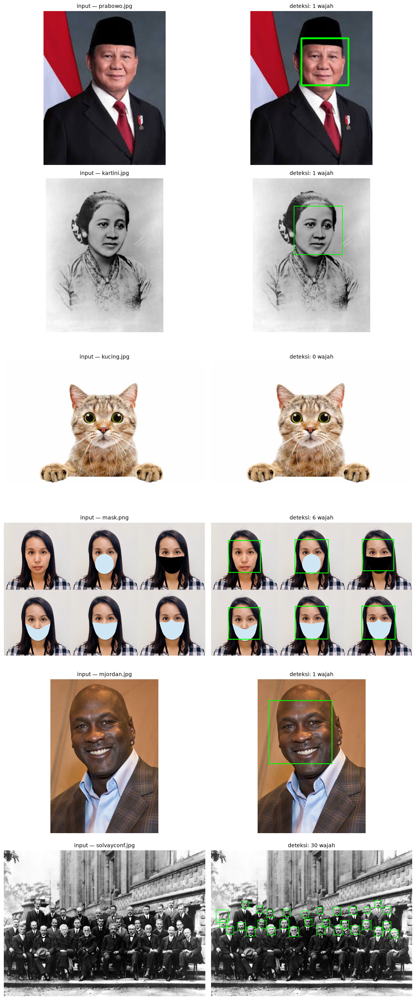

In [13]:
# ============================================================
# 9. Face Detection pada beberapa citra
# ============================================================
daftar_gambar = ['prabowo.jpg', 'kartini.jpg', 'kucing.jpg',
                 'mask.png', 'mjordan.jpg', 'solvayconf.jpg']

fig, ax = plt.subplots(len(daftar_gambar), 2, figsize=(11, 4.4 * len(daftar_gambar)))

for baris, nama in enumerate(daftar_gambar):
    asli = baca(nama)
    abu = cv2.cvtColor(asli, cv2.COLOR_BGR2GRAY)

    roi_wajah = cascade_wajah.detectMultiScale(abu,
                                               scaleFactor=1.05,
                                               minNeighbors=5,
                                               minSize=(20, 20))

    hasil = asli.copy()
    for (x, y, w, h) in roi_wajah:
        cv2.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # kiri: citra asli, kanan: hasil deteksi
    ax[baris, 0].imshow(cv2.cvtColor(asli, cv2.COLOR_BGR2RGB))
    ax[baris, 0].set_title(f'input — {nama}', fontsize=10)
    ax[baris, 0].axis('off')

    ax[baris, 1].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB))
    ax[baris, 1].set_title(f'deteksi: {len(roi_wajah)} wajah', fontsize=10)
    ax[baris, 1].axis('off')

    print(f'{nama:<24} -> {len(roi_wajah)} wajah')

plt.tight_layout()
plt.show()

## 10. Deteksi Wajah Kucing

Pada percobaan sebelumnya wajah kucing **tidak terdeteksi** karena cascade yang dipakai adalah
cascade wajah **manusia**. Solusinya adalah memakai pretrained feature khusus kucing yang sudah
disediakan OpenCV: **`haarcascade_frontalcatface.xml`**.

Parameter `scaleFactor` dibuat lebih rapat (`1.05`) dan `minNeighbors` lebih kecil (`3`) agar
wajah kucing yang tidak menghadap kamera tetap terdeteksi.

Dengan cascade wajah manusia : 0 wajah
Dengan cascade wajah kucing  : 1 wajah


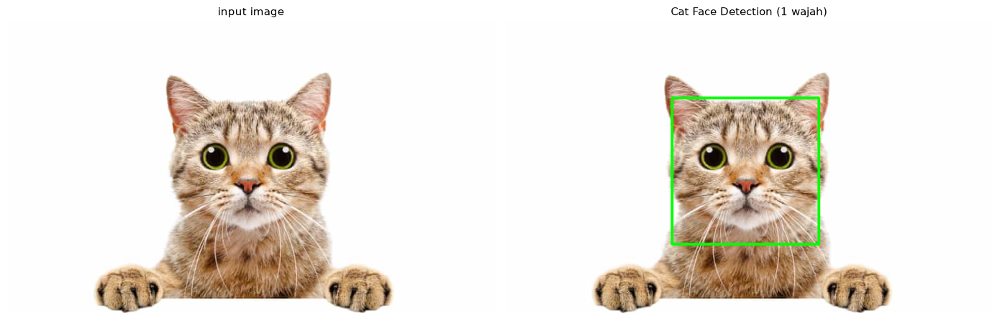

In [14]:
# ============================================================
# 10. Deteksi wajah kucing dengan haarcascade_frontalcatface.xml
# ============================================================
kucing = baca('kucing.jpg')
kucing_gray = cv2.cvtColor(kucing, cv2.COLOR_BGR2GRAY)

# bukti: cascade wajah manusia gagal
uji_manusia = cascade_wajah.detectMultiScale(kucing_gray, 1.05, 5, minSize=(20, 20))
print('Dengan cascade wajah manusia :', len(uji_manusia), 'wajah')

# cascade khusus kucing
roi_kucing = cascade_kucing.detectMultiScale(kucing_gray,
                                             scaleFactor=1.05,
                                             minNeighbors=3,
                                             minSize=(50, 50))

# buang kotak yang tumpang tindih (kadang wajah & hidung terdeteksi terpisah)
def hapus_tumpang_tindih(kotak, toleransi=0.4):
    kotak = sorted(kotak, key=lambda r: -r[2] * r[3])     # terbesar dulu
    hasil = []
    for (x, y, w, h) in kotak:
        tumpang = False
        for (X, Y, W, H) in hasil:
            xa, ya = max(x, X), max(y, Y)
            xb, yb = min(x + w, X + W), min(y + h, Y + H)
            if xa < xb and ya < yb:
                inter = (xb - xa) * (yb - ya)
                if inter / (w * h) > toleransi:
                    tumpang = True
                    break
        if not tumpang:
            hasil.append((x, y, w, h))
    return hasil

roi_kucing = hapus_tumpang_tindih(roi_kucing)
print('Dengan cascade wajah kucing  :', len(roi_kucing), 'wajah')

hasil_kucing = kucing.copy()
for (x, y, w, h) in roi_kucing:
    cv2.rectangle(hasil_kucing, (x, y), (x + w, y + h), (0, 255, 0), 3)

tampil_baris([kucing, hasil_kucing],
             ['input image', f'Cat Face Detection ({len(roi_kucing)} wajah)'],
             ukuran=(14, 5))

## 11. Eyes Detection pada Wajah Pak Prabowo

Deteksi mata dilakukan **di dalam ROI wajah** (bukan pada seluruh citra) agar hasilnya akurat.
ROI wajah dibagi dua: bagian atas untuk mata, sehingga pencarian lebih terarah.

Wajah terdeteksi: 1
  mata terdeteksi: 2


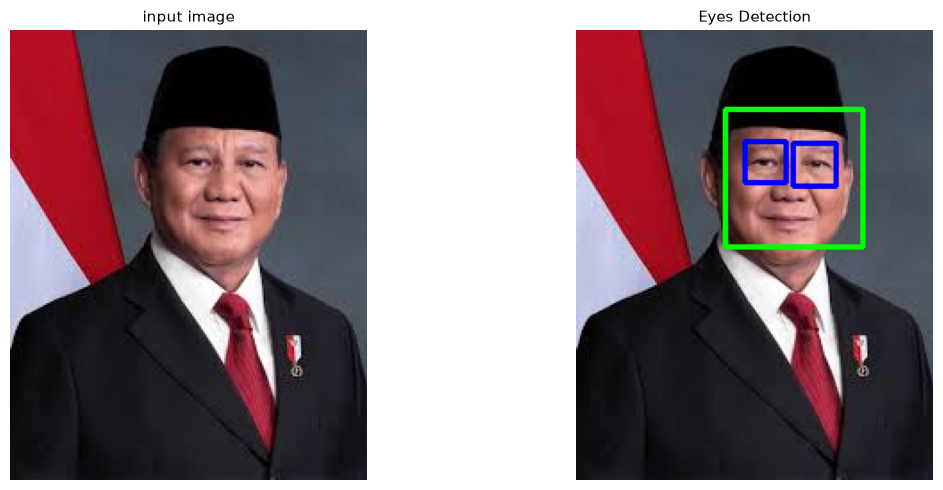

In [15]:
# ============================================================
# 11. Eyes Detection pada wajah Pak Prabowo
# ============================================================
prabowo = baca('prabowo.jpg')
prabowo_gray = cv2.cvtColor(prabowo, cv2.COLOR_BGR2GRAY)

wajah = cascade_wajah.detectMultiScale(prabowo_gray, 1.05, 5, minSize=(30, 30))
print('Wajah terdeteksi:', len(wajah))

hasil_mata = prabowo.copy()
for (x, y, w, h) in wajah:
    # gambar kotak wajah (hijau)
    cv2.rectangle(hasil_mata, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # ROI wajah untuk pencarian mata
    roi_gray = prabowo_gray[y:y + h, x:x + w]
    roi_warna = hasil_mata[y:y + h, x:x + w]

    mata = cascade_mata.detectMultiScale(roi_gray,
                                         scaleFactor=1.05,
                                         minNeighbors=5,
                                         minSize=(10, 10))
    print('  mata terdeteksi:', len(mata))
    for (ex, ey, ew, eh) in mata:
        cv2.rectangle(roi_warna, (ex, ey), (ex + ew, ey + eh), (255, 0, 0), 2)

tampil_baris([prabowo, hasil_mata],
             ['input image', 'Eyes Detection'],
             ukuran=(13, 5))

## 12. Deteksi Senyuman pada Gambar People

Cascade `haarcascade_smile.xml` sangat sensitif, sehingga:

* pencarian dilakukan **hanya pada bagian bawah ROI wajah** (area mulut),
* citra diperbesar 2× agar fitur mulut lebih jelas,
* `minNeighbors` dinaikkan (`10`) supaya tidak muncul kotak palsu.

Kotak hijau = wajah, kotak merah = senyuman.

Wajah terdeteksi: 9
Senyuman terdeteksi: 4


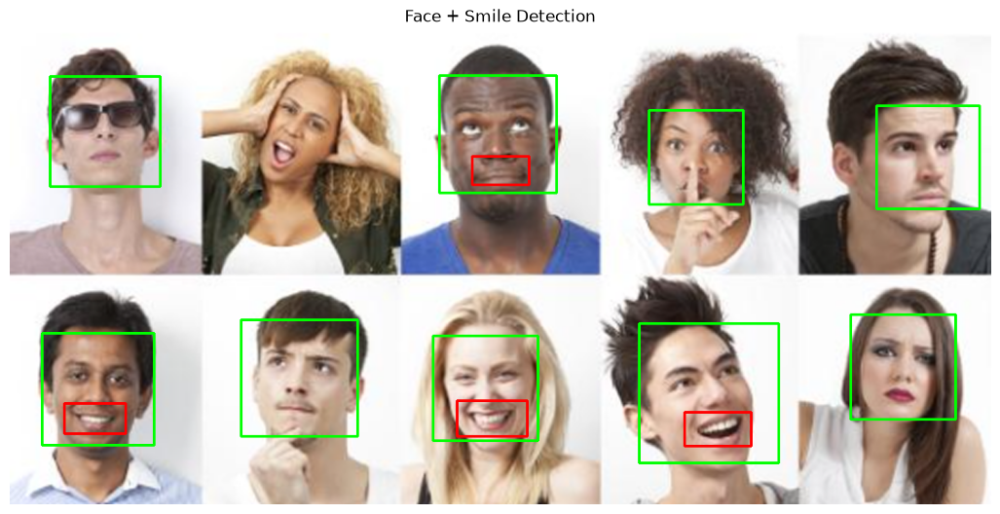

In [16]:
# ============================================================
# 12. Smile Detection pada gambar people
# ============================================================
people = baca('Screenshot 2026-11-02 084034.png')

# perbesar 2x agar fitur mulut lebih jelas
people_besar = cv2.resize(people, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
people_gray = cv2.cvtColor(people_besar, cv2.COLOR_BGR2GRAY)

wajah_people = cascade_wajah.detectMultiScale(people_gray, 1.05, 5, minSize=(40, 40))
print('Wajah terdeteksi:', len(wajah_people))

hasil_senyum = people_besar.copy()
jumlah_senyum = 0

for (x, y, w, h) in wajah_people:
    cv2.rectangle(hasil_senyum, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # area mulut = separuh bawah wajah
    y_mulut = y + int(h * 0.5)
    roi_mulut = people_gray[y_mulut:y + h, x:x + w]

    senyum = cascade_senyum.detectMultiScale(roi_mulut,
                                             scaleFactor=1.3,
                                             minNeighbors=10,
                                             minSize=(20, 20))
    for (sx, sy, sw, sh) in senyum:
        jumlah_senyum += 1
        cv2.rectangle(hasil_senyum,
                      (x + sx, y_mulut + sy),
                      (x + sx + sw, y_mulut + sy + sh),
                      (0, 0, 255), 2)

print('Senyuman terdeteksi:', jumlah_senyum)
tampil(hasil_senyum, 'Face + Smile Detection', ukuran=(13, 7))

## 13. Face Tracking dengan Google Colab

Google Colab **tidak dapat mengakses webcam** secara langsung, sehingga diperlukan **JavaScript**
untuk mengambil frame kamera lalu mengirimkannya ke Python. Cuplikan di bawah ini hanya berjalan
di Google Colab; ketika notebook dijalankan secara lokal, cell akan menampilkan keterangan saja
(tidak error).

Alur kerja:

1. JavaScript membuka kamera dan mengambil frame → dikirim ke Python sebagai data URL.
2. Python men-decode frame menjadi citra OpenCV.
3. `detectMultiScale()` mencari wajah pada frame.
4. Kotak wajah digambar, frame dikembalikan ke JavaScript untuk ditampilkan.
5. Proses diulang terus-menerus (tracking).

Tutorial rujukan: <https://www.youtube.com/watch?v=YjWh7QvVH60>

In [ ]:
# ============================================================
# 13. Face Tracking dengan webcam (khusus Google Colab)
# ============================================================
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not IN_COLAB:
    print('Cell ini hanya berjalan di Google Colab (butuh akses webcam via JavaScript).')
    print('Jika dijalankan di Colab, kamera akan terbuka dan wajah akan diberi kotak')
    print('secara real-time (face tracking).')
else:
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    from base64 import b64decode
    import PIL.Image
    import io

    # ---------- JavaScript: ambil frame dari webcam ----------
    JS_AMBIL = Javascript('''
    async function ambilFrame(quality) {
      if (window.stream === undefined) {
        const video = document.createElement('video');
        video.style.display = 'none';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        document.body.appendChild(video);
        video.srcObject = stream;
        await video.play();
        window.video = video;
        window.canvas = document.createElement('canvas');
        window.stream = stream;
      }
      const w = window.video.videoWidth, h = window.video.videoHeight;
      window.canvas.width = w; window.canvas.height = h;
      window.canvas.getContext('2d').drawImage(window.video, 0, 0, w, h);
      return window.canvas.toDataURL('image/jpeg', quality);
    }
    ''')

    # ---------- JavaScript: tampilkan hasil ----------
    JS_TAMPIL = Javascript('''
    async function tampilFrame(uri) {
      if (window.gambar === undefined) {
        window.gambar = document.createElement('img');
        window.gambar.style.width = '640px';
        document.body.appendChild(window.gambar);
      }
      window.gambar.src = uri;
    }
    ''')

    def ambil_frame(kualitas=0.8):
        display(JS_AMBIL)
        data = eval_js('ambilFrame({})'.format(kualitas))
        biner = b64decode(data.split(',')[1])
        return cv2.cvtColor(np.array(PIL.Image.open(io.BytesIO(biner))), cv2.COLOR_RGB2BGR)

    def kirim_frame(img):
        _, buffer = cv2.imencode('.jpg', img)
        from base64 import b64encode
        data = 'data:image/jpeg;base64,' + b64encode(buffer).decode('utf-8')
        display(JS_TAMPIL)
        eval_js('tampilFrame("{}")'.format(data))

    # ---------- loop face tracking ----------
    try:
        for i in range(50):                      # 50 frame
            frame = ambil_frame()
            abu = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            wajah = cascade_wajah.detectMultiScale(abu, 1.1, 5, minSize=(60, 60))
            for (x, y, w, h) in wajah:
                cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
                cv2.putText(frame, 'Face', (x, y - 8),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
            kirim_frame(frame)
    except Exception as e:
        print('Tracking dihentikan:', e)

Cell ini hanya berjalan di Google Colab (butuh akses webcam via JavaScript).
Jika dijalankan di Colab, kamera akan terbuka dan wajah akan diberi kotak
secara real-time (face tracking).


## 14. Blurring pada Bagian Wajah yang Terdeteksi

Setelah wajah ditemukan, area wajah diganti dengan versi **blur** memakai `cv2.medianBlur()`.
Median blur dipilih karena efektif menyamarkan detail namun tetap menjaga bentuk objek
(privasi terjaga). Nilai kernel harus **bilangan ganjil**.

mjordan.jpg: 1 wajah diburamkan


jokowi.jpg: 1 wajah diburamkan


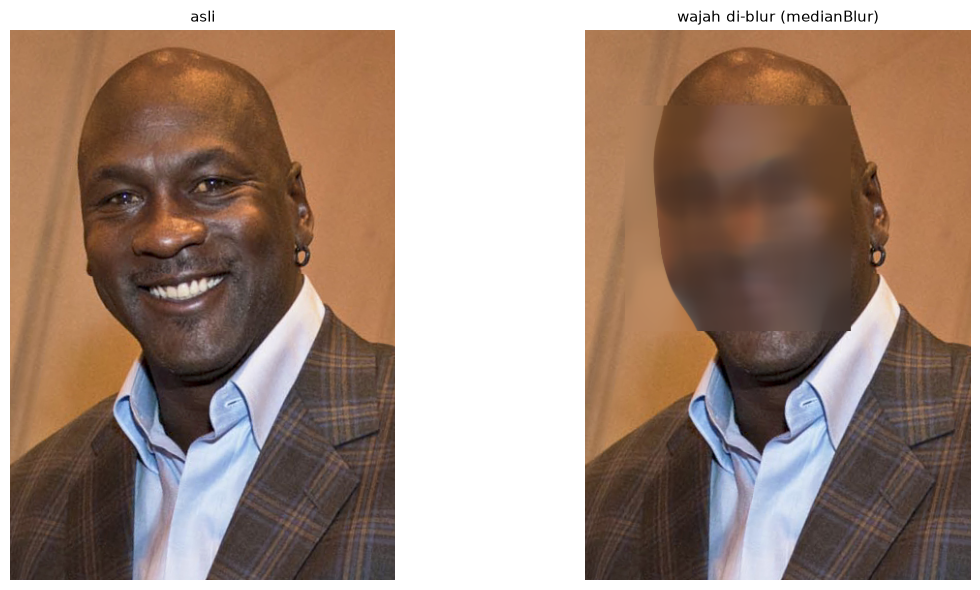

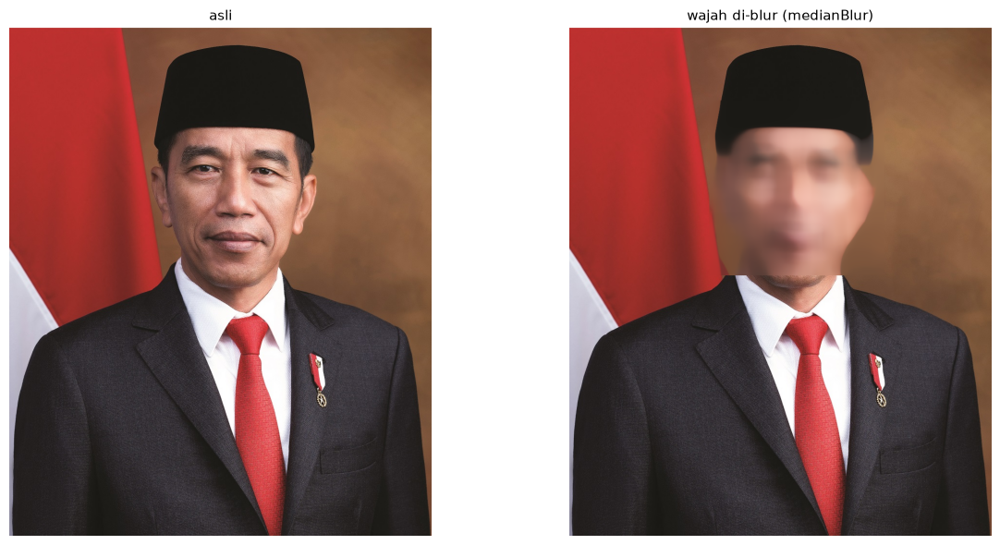

In [18]:
# ============================================================
# 14. Blurring pada wajah yang terdeteksi
# ============================================================
def blur_wajah(nama_file, kernel=51):
    citra = baca(nama_file)
    abu = cv2.cvtColor(citra, cv2.COLOR_BGR2GRAY)
    wajah = cascade_wajah.detectMultiScale(abu, 1.05, 5, minSize=(30, 30))

    hasil = citra.copy()
    for (x, y, w, h) in wajah:
        roi = hasil[y:y + h, x:x + w]
        hasil[y:y + h, x:x + w] = cv2.medianBlur(roi, kernel)

    print(f'{nama_file}: {len(wajah)} wajah diburamkan')
    return citra, hasil


asli_mj, blur_mj = blur_wajah('mjordan.jpg')
asli_jo, blur_jo = blur_wajah('jokowi.jpg')

tampil_baris([asli_mj, blur_mj], ['asli', 'wajah di-blur (medianBlur)'], ukuran=(13, 6))
tampil_baris([asli_jo, blur_jo], ['asli', 'wajah di-blur (medianBlur)'], ukuran=(13, 6))

## 15. Mengolah Gambar KTM

Tahapan pengolahan gambar KTM:

1. Membaca citra KTM.
2. Menampilkan citra asli dan hasil *cropping*/perbaikan kontras.
3. Menyiapkan **scene** baru: KTM diletakkan bersama barang lain (contoh: di atas laptop)
   dengan rotasi tertentu, sebagai bahan uji pada soal berikutnya.

Ukuran citra KTM: (278, 445, 3)


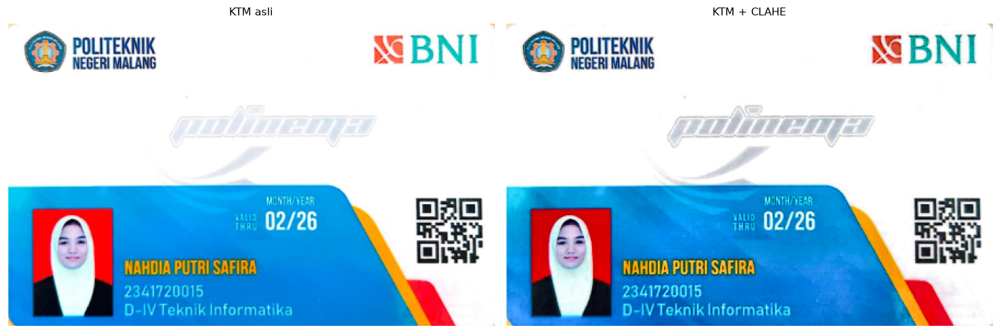

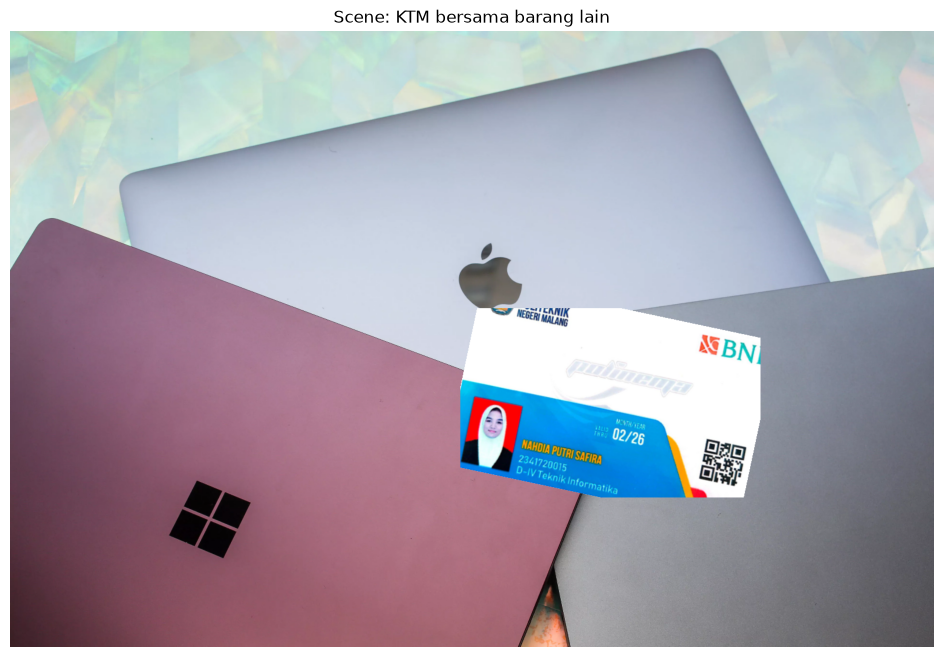

In [19]:
# ============================================================
# 15. Olah gambar KTM
# ============================================================
ktm = baca('Screenshot 2026-11-02 084058.png')
print('Ukuran citra KTM:', ktm.shape)

# --- perbaikan kontras dengan CLAHE (opsional, agar teks lebih jelas) ---
lab = cv2.cvtColor(ktm, cv2.COLOR_BGR2LAB)
l, a, b = cv2.split(lab)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
ktm_cerah = cv2.cvtColor(cv2.merge([clahe.apply(l), a, b]), cv2.COLOR_LAB2BGR)

tampil_baris([ktm, ktm_cerah], ['KTM asli', 'KTM + CLAHE'], ukuran=(14, 5))

# --- siapkan scene: KTM di antara barang lain (di atas laptop) ---
latar = cv2.resize(baca('laptop.jpg'), (1600, 1067))

kartu = cv2.resize(ktm, (520, 328))
H_kartu, W_kartu = kartu.shape[:2]
M = cv2.getRotationMatrix2D((W_kartu / 2, H_kartu / 2), -12, 1.0)
kartu_putar = cv2.warpAffine(kartu, M, (W_kartu, H_kartu),
                             flags=cv2.INTER_CUBIC, borderValue=(255, 255, 255))

# mask agar sudut hasil rotasi tidak ikut menempel
mask = np.full((H_kartu, W_kartu), 255, np.uint8)
mask_putar = cv2.warpAffine(mask, M, (W_kartu, H_kartu), flags=cv2.INTER_NEAREST,
                            borderValue=0)

x0, y0 = 780, 480
roi = latar[y0:y0 + H_kartu, x0:x0 + W_kartu]
roi[mask_putar > 0] = kartu_putar[mask_putar > 0]
latar[y0:y0 + H_kartu, x0:x0 + W_kartu] = roi

cv2.imwrite(path('ktm_scene.jpg'), latar)
tampil(latar, 'Scene: KTM bersama barang lain', ukuran=(12, 8))

## 16. Deteksi Obyek KTM dengan Konsep Feature Matching

Berbeda dengan template matching yang menuntut template **persis sama** (ukuran & orientasi),
**feature matching** hanya membutuhkan *keypoint* yang khas, sehingga objek tetap dikenali
walaupun **berbeda ukuran, berotasi, dan berubah skala**.

**Metode:** SIFT + Brute-Force Matcher + **Lowe's Ratio Test** + **RANSAC Homography**.

Langkah:

1. `SIFT_create()` mengekstrak keypoint & deskriptor dari KTM dan dari scene.
2. `BFMatcher.knnMatch(k=2)` mencari 2 kandidat terdekat untuk setiap deskriptor.
3. **Ratio test** (`distance < 0.75 × distance_kandidat_kedua`) menyaring kecocokan yang lemah.
4. `findHomography(RANSAC)` menghitung transformasi perspektif antara KTM dan scene.
5. `perspectiveTransform()` memetakan sudut KTM ke scene → digambar dengan `polylines()`.

Keypoint KTM   : 527
Keypoint scene : 926
Kecocokan bagus: 316


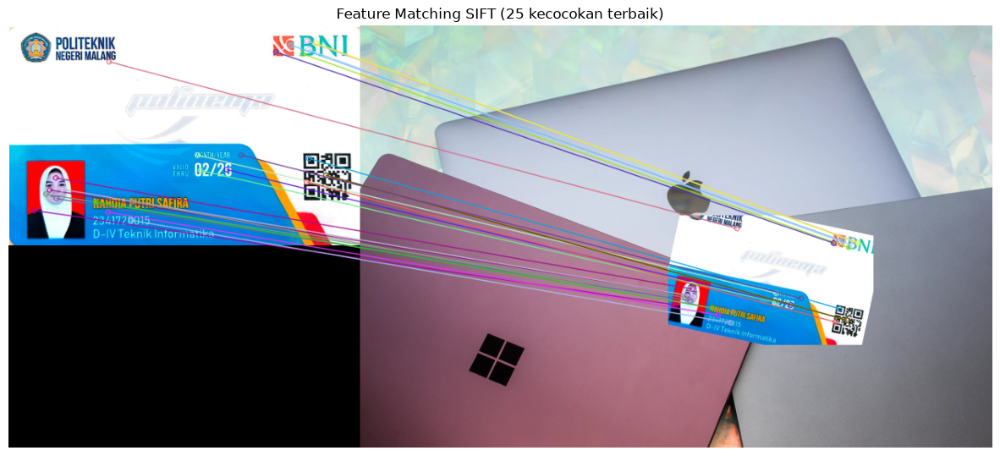

In [20]:
# ============================================================
# 16. Deteksi obyek KTM dengan Feature Matching (SIFT)
# ============================================================
scene = baca('ktm_scene.jpg')

sift = cv2.SIFT_create()

# --- ekstraksi keypoint & deskriptor ---
kp_ktm, des_ktm = sift.detectAndCompute(cv2.cvtColor(ktm, cv2.COLOR_BGR2GRAY), None)
kp_scene, des_scene = sift.detectAndCompute(cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY), None)

print('Keypoint KTM   :', len(kp_ktm))
print('Keypoint scene :', len(kp_scene))

# --- Brute-Force matching + ratio test ---
bf = cv2.BFMatcher()
pasangan = bf.knnMatch(des_ktm, des_scene, k=2)

baik = []
for m, n in pasangan:
    if m.distance < 0.75 * n.distance:      # Lowe's ratio test
        baik.append(m)
print('Kecocokan bagus:', len(baik))

# --- visualisasi 25 kecocokan terbaik ---
# scene dikecilkan agar proporsinya seimbang dengan citra KTM pada saat digambar berdampingan
scene_kecil = cv2.resize(scene, None, fx=0.5, fy=0.5)
kp_scene_kecil, des_scene_kecil = sift.detectAndCompute(
    cv2.cvtColor(scene_kecil, cv2.COLOR_BGR2GRAY), None)

pasangan2 = bf.knnMatch(des_ktm, des_scene_kecil, k=2)
baik_kecil = [m for m, n in pasangan2 if m.distance < 0.75 * n.distance]

baik_urut = sorted(baik_kecil, key=lambda m: m.distance)[:25]
gambar_match = cv2.drawMatches(ktm, kp_ktm, scene_kecil, kp_scene_kecil, baik_urut, None,
                               flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
tampil(gambar_match, 'Feature Matching SIFT (25 kecocokan terbaik)', ukuran=(15, 7))

Homography berhasil : True
Jumlah inlier       : 306


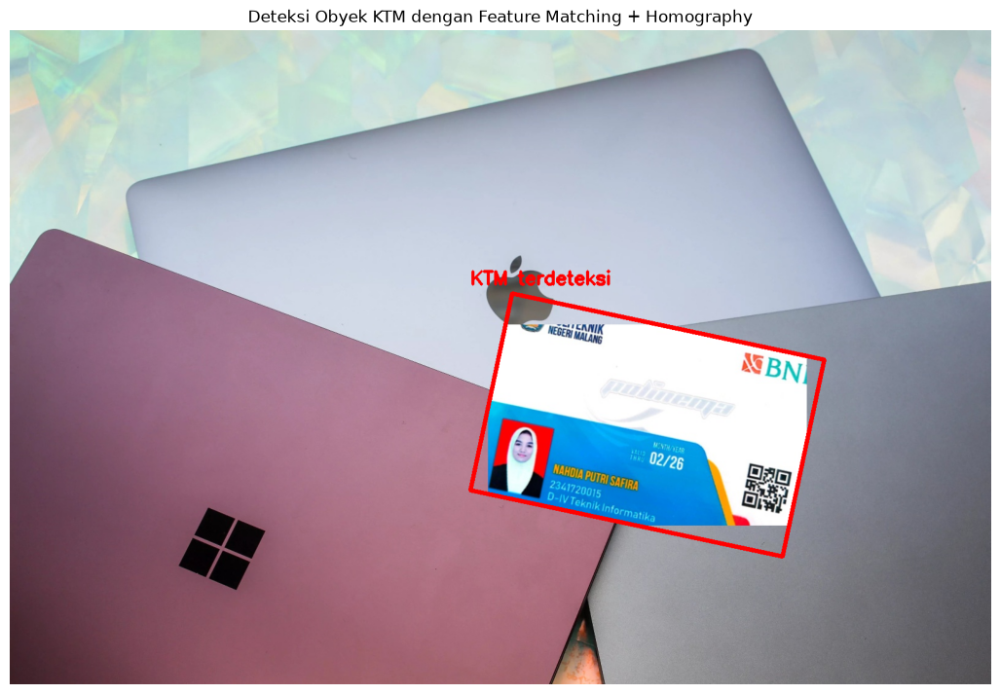

In [21]:
# --- Homography + RANSAC untuk menemukan lokasi KTM pada scene ---
if len(baik) >= 4:
    titik_ktm = np.float32([kp_ktm[m.queryIdx].pt for m in baik]).reshape(-1, 1, 2)
    titik_scene = np.float32([kp_scene[m.trainIdx].pt for m in baik]).reshape(-1, 1, 2)

    H, mask_inlier = cv2.findHomography(titik_ktm, titik_scene, cv2.RANSAC, 5.0)
    print('Homography berhasil :', H is not None)
    print('Jumlah inlier       :', int(mask_inlier.sum()) if mask_inlier is not None else 0)

    h_ktm, w_ktm = ktm.shape[:2]
    sudut_ktm = np.float32([[0, 0],
                            [0, h_ktm],
                            [w_ktm, h_ktm],
                            [w_ktm, 0]]).reshape(-1, 1, 2)

    sudut_scene = cv2.perspectiveTransform(sudut_ktm, H).astype(np.int32)

    hasil_deteksi = scene.copy()
    cv2.polylines(hasil_deteksi, [sudut_scene], True, (0, 0, 255), 5)
    cv2.putText(hasil_deteksi, 'KTM terdeteksi', (sudut_scene[:, 0, 0].min(),
                sudut_scene[:, 0, 1].min() - 15),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 3)

    tampil(hasil_deteksi, 'Deteksi Obyek KTM dengan Feature Matching + Homography',
           ukuran=(13, 9))
else:
    print('Kecocokan tidak cukup untuk menghitung homography.')

---
## Kesimpulan

1. **Template Matching** (`cv2.matchTemplate`) bekerja baik bila template **identik** dengan objek
   pada citra (ukuran, rotasi, dan skala sama). Enam metode tersedia; `TM_SQDIFF*` mencari nilai
   minimum, sedangkan `TM_CCORR*` dan `TM_CCOEFF*` mencari nilai maksimum.
2. Template matching dapat diimplementasikan **manual** memakai integral image + FFT untuk
   menghitung NCC. Dengan **Non-Maximum Suppression**, metode ini mampu menemukan **banyak objek**
   sekaligus (kasus pulau buatan Bahrain).
3. **Edge detection**: Sobel menghitung gradien arah X/Y, Laplacian memakai turunan kedua
   (sensitif noise sehingga perlu Gaussian), dan Canny memberi hasil tepi paling tipis serta
   paling bersih karena memakai non-maximum suppression + hysteresis.
4. **Corner detection**: Harris memakai nilai respons `R`, Shi-Tomasi cukup memakai `λmin`
   sehingga lebih sederhana dan cepat.
5. **Grid detection** dengan Hough Transform memerlukan tahapan Canny → dilasi → erosi →
   `HoughLines` → penggabungan garis mirip agar diperoleh garis grid yang rapi.
6. **Contour detection** membutuhkan citra biner; `findContours()` mengembalikan daftar kurva
   tertutup yang merepresentasikan bentuk objek.
7. **Haar Cascade (Viola-Jones)** sangat cepat karena memakai *integral image* dan
   *cascade classifier*. Kuncinya adalah memilih **file XML yang tepat**: cascade wajah manusia
   gagal mendeteksi kucing, dan berhasil setelah memakai `haarcascade_frontalcatface.xml`.
8. **Feature Matching (SIFT)** jauh lebih tangguh daripada template matching karena **invariant**
   terhadap skala dan rotasi. Kombinasi **ratio test + RANSAC homography** membuat deteksi objek
   (KTM) akurat walaupun objek berotasi dan berada di antara barang lain.